# During-Inference Ensemble S-C: M1→M4 Reasoning ReviewerBerbeda dari S-B (binary gate) dimana M4 hanya output YES/NO,notebook ini meminta M4 untuk **melakukan reasoning sendiri** sebelum memberikan klasifikasi.```CXR Image → M1 (NV-Reason-CXR-3B) → reasoning + prediksi                                              ↓CXR Image + M1's reasoning → M4 (MedGemma-4B-IT) → reasoning review + klasifikasi```### S-B vs S-C| Aspek | S-B (Binary Gate) | S-C (Reasoning Reviewer) ||-------|-------------------|--------------------------|| M4 Output | YES/NO saja | Reasoning + klasifikasi || Inference Time | ~0.7s | ~10-30s || Interpretability | Low | High || Research Q | Apakah M4 bisa filter M1? | Apakah reasoning review lebih baik dari binary? |**M1 data sudah ada** dari Exp1 v2 — hanya M4 yang perlu inference baru.

## 1 — Setup & Imports

In [1]:
import sys
import json
import time
import re
from pathlib import Path
from datetime import datetime

import pandas as pd
import numpy as np
import torch
from PIL import Image
from tqdm.auto import tqdm

# Add src to path
sys.path.insert(0, str(Path('src').resolve()))
from during_ensemble import (
    USER_QUERY_REVIEWER,
    build_reviewer_user_text, build_few_shot_context_v2,
    load_m1_results, get_m1_output,
    load_checkpoint, append_jsonl,
)
from evaluate import extract_diagnosis, compute_classification_metrics

print(f'PyTorch: {torch.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

/data/arta/envs/thoraxai/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.10.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 5090
VRAM: 33.7 GB


## 2 — Configuration

In [2]:
# ════════════════════════════════════════════════════════════════════
# KONFIGURASI — SESUAIKAN PATH INI
# ════════════════════════════════════════════════════════════════════

# Model M4 (MedGemma-4B-IT) — path ke model weights
M4_MODEL_PATH = "../models/MedGemma-4B-IT"  # <-- SESUAIKAN

# M1 existing results (dari Exp1 v2)
M1_RESULTS_PATH = Path("result-M1/all_results.jsonl")

# Few-shot example pool CSVs
CHEXPERT_PTX_CSV  = "../data/chexpert_ptx_positive.csv"   # <-- SESUAIKAN
CHEXPERT_NORM_CSV = "../data/chexpert_ptx_negative.csv"   # <-- SESUAIKAN

# Test set image directories
CHEXPERT_TEST_NORMAL_DIR = "../data/chexpert_plus/images/internal_test_normal"  # <-- SESUAIKAN
CHEXPERT_TEST_PTX_DIR    = "../data/chexpert_plus/images/internal_test_pneumothorax"  # <-- SESUAIKAN
CHEXPERT_TEST_CSV        = "../data/chexpert_internal_test.csv"  # <-- SESUAIKAN

RSUNAIR_IMAGES_NORMAL = "../data/rs_unair/images/normal"  # <-- SESUAIKAN
RSUNAIR_IMAGES_PTX    = "../data/rs_unair/images/pneumothorax"  # <-- SESUAIKAN
RSUNAIR_LABELS_CSV    = "../data/rs_unair/labels.csv"  # <-- SESUAIKAN

# Few-shot image pool root (untuk example_selector)
POOL_IMAGES_ROOT = "../data/chexpert_plus/images"  # <-- SESUAIKAN

# Experiment config
K_SHOTS = [0, 1, 4]
SEEDS = [0, 1, 2, 3, 4]
MAX_NEW_TOKENS = 1024
TEMPERATURE = 0.1
TOP_P = 0.9

# Output — DIFFERENT from S-B
OUTPUT_DIR = Path("results-during-ensemble-m1-m4-reasoning")
OUTPUT_DIR.mkdir(exist_ok=True)
CHECKPOINT_PATH = OUTPUT_DIR / "checkpoint_during_ensemble_m1_m4_reasoning.jsonl"

print("Config loaded.")
print(f"  M4 model: {M4_MODEL_PATH}")
print(f"  K-shots: {K_SHOTS}")
print(f"  Seeds: {SEEDS}")
print(f"  Output: {OUTPUT_DIR}")

Config loaded.
  M4 model: ../models/MedGemma-4B-IT
  K-shots: [0, 1, 4]
  Seeds: [0, 1, 2, 3, 4]
  Output: results-during-ensemble-m1-m4-reasoning


## 3 — Load M1 Existing Results

In [3]:
df_m1 = load_m1_results(M1_RESULTS_PATH)

# Filter to k_shots we need
df_m1_filtered = df_m1[df_m1['k_shot'].isin(K_SHOTS)].copy()
print(f"\nFiltered to k={K_SHOTS}: {len(df_m1_filtered)} records")
print(df_m1_filtered.groupby(['k_shot', 'test_set']).size().unstack(fill_value=0))

Loaded M1 results: 11950 records
  k_shots: [np.int64(0), np.int64(1), np.int64(2), np.int64(4), np.int64(8)]
  seeds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
  test_sets: ['CheXpert Plus (Internal)', 'RS UNAIR (External)']

Filtered to k=[0, 1, 4]: 7170 records
test_set  CheXpert Plus (Internal)  RS UNAIR (External)
k_shot                                                 
0                             1000                 1390
1                             1000                 1390
4                             1000                 1390


## 4 — Load Few-Shot Example Selector

In [4]:
try:
    from example_selector import FewShotSelector
    selector = FewShotSelector(
        positive_csv=CHEXPERT_PTX_CSV,
        negative_csv=CHEXPERT_NORM_CSV,
        images_root=POOL_IMAGES_ROOT,
    )
    USE_SELECTOR = True
    print("FewShotSelector loaded successfully.")
except Exception as e:
    USE_SELECTOR = False
    print(f"FewShotSelector not available: {e}")
    print("Few-shot context will be skipped — only M1's output will be given to M4.")

[FewShotSelector] Pool loaded — PTX: 150, Normal: 150
FewShotSelector loaded successfully.


## 5 — Load Test Sets

In [5]:
def load_test_images(csv_path, normal_dir, ptx_dir, name):
    """Load test set image paths and labels."""
    df = pd.read_csv(csv_path)
    rows = []
    
    if 'file_id' in df.columns:
        # CheXpert format
        for _, r in df.iterrows():
            fid = r['file_id']
            label_int = 1 if r['label'] == 'pneumothorax' else 0
            img_dir = ptx_dir if label_int == 1 else normal_dir
            img_path = Path(img_dir) / f"{fid}.jpg"
            if not img_path.exists():
                img_path = Path(img_dir) / f"{fid}.png"
            rows.append({'image_id': fid, 'ground_truth': label_int, 'image_path': str(img_path)})
    elif 'image_id' in df.columns:
        # RS UNAIR format
        for _, r in df.iterrows():
            fname = r['image_id']
            if not fname.endswith(('.png', '.jpg')):
                fname = f"{fname}.png"
            label_int = int(r['label'])
            img_dir = ptx_dir if label_int == 1 else normal_dir
            img_path = Path(img_dir) / fname
            rows.append({'image_id': Path(fname).stem, 'ground_truth': label_int, 'image_path': str(img_path)})
    else:
        raise ValueError(f"Unknown CSV format: {df.columns.tolist()}")
    
    result = pd.DataFrame(rows)
    print(f"  {name}: {len(result)} images (PTX={result['ground_truth'].sum()}, Normal={(result['ground_truth']==0).sum()})")
    return result


print("Loading test sets...")
test_sets = [
    {
        'name': 'CheXpert Plus (Internal)',
        'df': load_test_images(CHEXPERT_TEST_CSV, CHEXPERT_TEST_NORMAL_DIR, CHEXPERT_TEST_PTX_DIR, 'CheXpert'),
    },
    {
        'name': 'RS UNAIR (External)',
        'df': load_test_images(RSUNAIR_LABELS_CSV, RSUNAIR_IMAGES_NORMAL, RSUNAIR_IMAGES_PTX, 'RS UNAIR'),
    },
]
print(f"\nTotal images per inference: {sum(ts['df'].shape[0] for ts in test_sets)}")

Loading test sets...
  CheXpert: 200 images (PTX=100, Normal=100)
  RS UNAIR: 278 images (PTX=173, Normal=105)

Total images per inference: 478


## 6 — Load M4 Model (MedGemma-4B-IT, Gemma 3)**PENTING:** Gemma 3 harus di-load dengan `bfloat16` compute dtype. float16 menyebabkan output pad tokens.

In [6]:
from transformers import AutoProcessor, BitsAndBytesConfig
from transformers import Gemma3ForConditionalGeneration

print(f"Loading M4 model: {M4_MODEL_PATH}")
print("Architecture: Gemma 3 (MedGemma-4B-IT)")
print("Quantization: 4-bit NF4 (bfloat16 compute)")

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
)

m4_processor = AutoProcessor.from_pretrained(M4_MODEL_PATH)

m4_model = Gemma3ForConditionalGeneration.from_pretrained(
    M4_MODEL_PATH,
    quantization_config=quant_config,
    device_map="auto",
)
m4_model.eval()

print(f"M4 loaded. Device: {m4_model.device}")
print(f"VRAM used: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

The image processor of type `Gemma3ImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


Loading M4 model: ../models/MedGemma-4B-IT
Architecture: Gemma 3 (MedGemma-4B-IT)
Quantization: 4-bit NF4 (bfloat16 compute)


Loading weights: 100%|██████████| 883/883 [00:00<00:00, 1216.01it/s]

M4 loaded. Device: cuda:0
VRAM used: 3.24 GB


## 7 — M4 Reasoning Reviewer Inference Function**Perbedaan dari S-B:** System prompt meminta M4 melakukan reasoning sendiri sebelum klasifikasi.M4 harus mengevaluasi klaim M1 dan memberikan assessment independen.

In [7]:
# ── System Prompt: Reasoning Reviewer v2 (balanced — no directional bias) ──
# v1 FAILED: "CORRECT any over-detection" + "if ambiguous → NO" caused always-NO (sensitivity=0.0)
# v2: neutral instructions, encourage evidence-based classification

SYSTEM_PROMPT_REASONING_REVIEWER = (
    "You are an expert radiologist assistant performing a second reading of a chest X-ray (CXR).\n\n"
    "A first reader (AI model) has already analyzed this image. "
    "Their full analysis is provided below.\n\n"
    "Your role:\n"
    "1. REVIEW the first reader's analysis — check if their observations match the radiographic evidence\n"
    "2. VERIFY specific findings — if the first reader identifies pneumothorax signs "
    "(e.g., visceral pleural line, absent lung markings, hyperlucency), look carefully at those areas\n"
    "3. PROVIDE YOUR OWN ASSESSMENT — describe what you observe in the image independently\n"
    "4. Make YOUR OWN independent classification based on the radiographic evidence\n\n"
    "Format your response as:\n"
    "FIRST READER EVALUATION: [2-3 sentences evaluating the first reader's claims]\n"
    "MY OBSERVATIONS: [2-3 sentences describing what you see in the image]\n"
    "CLASSIFICATION: [PNEUMOTHORAX DETECTED or NO PNEUMOTHORAX DETECTED]\n\n"
    "Important:\n"
    "- Base your classification on radiographic evidence visible in the image.\n"
    "- If you see signs consistent with pneumothorax (even subtle), classify as PNEUMOTHORAX DETECTED.\n"
    "- If the lung fields are clear with no evidence of pneumothorax, classify as NO PNEUMOTHORAX DETECTED."
)


def generate_m4_reasoning_review(
    image_path: str,
    m1_output: str,
    few_shot_context: str = "",
    max_new_tokens: int = 1024,
) -> tuple:
    """
    Run M4 as reasoning reviewer with M1's output as context.
    
    Unlike S-B (binary gate), M4 generates its own reasoning before classification.
    
    Returns: (generated_text, inference_time_seconds)
    """
    # Load image
    img = Image.open(image_path)
    if img.mode != 'RGB':
        img = img.convert('RGB')
    
    # Build user text with M1's output
    user_text = build_reviewer_user_text(m1_output, few_shot_context)
    
    # Build messages in Gemma 3 chat format
    content_parts = []
    if user_text:
        content_parts.append({"type": "text", "text": user_text})
    content_parts.append({"type": "image", "image": img})
    content_parts.append({"type": "text", "text": USER_QUERY_REVIEWER})
    
    messages = [
        {
            "role": "system",
            "content": [{"type": "text", "text": SYSTEM_PROMPT_REASONING_REVIEWER}],
        },
        {
            "role": "user",
            "content": content_parts,
        },
    ]
    
    # Apply chat template
    text = m4_processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    
    # Process inputs
    inputs = m4_processor(
        text=text, images=[img], return_tensors="pt",
    ).to(m4_model.device)
    input_len = inputs["input_ids"].shape[1]
    
    # Generate — greedy decoding for reproducibility
    t0 = time.time()
    with torch.no_grad():
        output_ids = m4_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
        )
    elapsed = time.time() - t0
    
    # Decode only new tokens
    generated_ids = output_ids[:, input_len:]
    result = m4_processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
    
    # Cleanup
    del inputs, output_ids, generated_ids
    torch.cuda.empty_cache()
    
    return result, elapsed


print("generate_m4_reasoning_review() defined — v2 balanced prompt")
print(f"System prompt length: {len(SYSTEM_PROMPT_REASONING_REVIEWER)} chars")

generate_m4_reasoning_review() defined — v2 balanced prompt
System prompt length: 1173 chars


## 7b — Quick Test (1 image)

In [8]:
# Test on 1 image to verify output format
img_row = test_sets[0]['df'].iloc[0]
m1_output = get_m1_output(df_m1, 0, 0, test_sets[0]['name'], img_row['image_id'])

test_text, test_time = generate_m4_reasoning_review(
    image_path=img_row['image_path'],
    m1_output=m1_output,
    max_new_tokens=MAX_NEW_TOKENS,
)

print(f"Inference time: {test_time:.1f}s")
print(f"Output length: {len(test_text)} chars")
print(f"\n{'='*60}")
print("M4 REASONING REVIEW OUTPUT:")
print(f"{'='*60}")
print(test_text)
print(f"\n{'='*60}")

# Verify classification can be extracted
pred = extract_diagnosis(test_text)
print(f"\nExtracted prediction: {pred} ({'PTX' if pred == 1 else 'Normal' if pred == 0 else 'INVALID'})")

Inference time: 3.1s
Output length: 520 chars

M4 REASONING REVIEW OUTPUT:
FIRST READER EVALUATION: The first reader has performed a thorough evaluation of the chest X-ray, including assessment of the lungs, pleura, mediastinum, heart, and bony structures. They have also identified and noted the absence of medical devices and foreign objects.

MY OBSERVATIONS: The lungs appear clear bilaterally with no evidence of consolidation, effusion, or masses. The costophrenic angles are sharp. The mediastinum is unremarkable. The heart size appears normal.

CLASSIFICATION: NO PNEUMOTHORAX DETECTED



Extracted prediction: 0 (Normal)


## 8 — Run During-Ensemble Inference (Reasoning Reviewer)Untuk setiap (k, seed, test_set, image):1. Ambil M1's generated_text dari data yang sudah ada2. Build prompt: system (reasoning reviewer) + M1 output + image + query3. M4 generates reasoning + classification4. Simpan ke checkpoint JSONL

In [11]:
# Load checkpoint (untuk resume jika terputus)
done_keys, existing_records = load_checkpoint(CHECKPOINT_PATH)
print(f"Checkpoint: {len(done_keys)} records already done.")

# Count total work
total_inferences = 0
for ts in test_sets:
    for k in K_SHOTS:
        for seed in SEEDS:
            for _, row in ts['df'].iterrows():
                key = (k, seed, ts['name'], row['image_id'])
                if key not in done_keys:
                    total_inferences += 1

print(f"Remaining inferences: {total_inferences}")
print(f"Estimated time: ~{total_inferences * 15 / 3600:.1f} hours (assuming ~15s per inference)")

Checkpoint: 10 records already done.
Remaining inferences: 7160
Estimated time: ~29.8 hours (assuming ~15s per inference)


In [12]:
# ═══════════════════════════════════════════════════════════
# MAIN INFERENCE LOOP — S-C Reasoning Reviewer
# ═══════════════════════════════════════════════════════════

batch_buffer = []
BATCH_SIZE = 10
errors = []

pbar = tqdm(total=total_inferences, desc="During-Ensemble M1→M4 (Reasoning)")

for k in K_SHOTS:
    for seed in SEEDS:
        # Get few-shot examples for this seed
        few_shot_context = ""
        if k > 0 and USE_SELECTOR:
            try:
                examples = selector.select(strategy="random", k=k, seed=seed)
                few_shot_context = build_few_shot_context_v2(examples, k)
            except Exception as e:
                print(f"Warning: Could not build few-shot context for k={k} seed={seed}: {e}")
                few_shot_context = ""
        
        for ts in test_sets:
            ts_name = ts['name']
            
            for _, img_row in ts['df'].iterrows():
                image_id = img_row['image_id']
                key = (k, seed, ts_name, image_id)
                
                if key in done_keys:
                    continue
                
                # Get M1's output
                m1_output = get_m1_output(df_m1, k, seed, ts_name, image_id)
                if m1_output is None:
                    errors.append(f"M1 output missing: k={k} seed={seed} {ts_name} {image_id}")
                    continue
                
                # Run M4 as reasoning reviewer
                try:
                    m4_text, m4_time = generate_m4_reasoning_review(
                        image_path=img_row['image_path'],
                        m1_output=m1_output,
                        few_shot_context=few_shot_context,
                        max_new_tokens=MAX_NEW_TOKENS,
                    )
                except Exception as e:
                    errors.append(f"M4 error: k={k} seed={seed} {ts_name} {image_id}: {e}")
                    m4_text = ""
                    m4_time = 0.0
                
                record = {
                    "experiment_type": "during_ensemble_reasoning",
                    "ensemble_method": "M1_to_M4_reasoning_reviewer",
                    "k_shot": k,
                    "strategy": "random",
                    "seed": seed,
                    "test_set": ts_name,
                    "image_id": image_id,
                    "ground_truth": int(img_row['ground_truth']),
                    "m1_generated_text": m1_output,
                    "m4_generated_text": m4_text,
                    "m4_inference_time": round(m4_time, 3),
                    "timestamp": datetime.now().isoformat(),
                }
                
                batch_buffer.append(record)
                done_keys.add(key)
                pbar.update(1)
                
                # Periodic checkpoint
                if len(batch_buffer) >= BATCH_SIZE:
                    append_jsonl(CHECKPOINT_PATH, batch_buffer)
                    batch_buffer = []

# Flush remaining
if batch_buffer:
    append_jsonl(CHECKPOINT_PATH, batch_buffer)
    batch_buffer = []

pbar.close()

print(f"\nDone! Total records: {len(done_keys)}")
if errors:
    print(f"Errors ({len(errors)}):")
    for e in errors[:10]:
        print(f"  {e}")


During-Ensemble M1→M4 (Reasoning):   0%|          | 11/7170 [02:13<24:05:11, 12.11s/it]

During-Ensemble M1→M4 (Reasoning): 100%|██████████| 7160/7160 [5:49:50<00:00,  2.93s/it]


Done! Total records: 7170


## 9 — Consolidate Results

In [13]:
# Load all results
records = []
with open(CHECKPOINT_PATH, encoding='utf-8') as f:
    for line in f:
        if line.strip():
            records.append(json.loads(line))

df_during = pd.DataFrame(records)
print(f"Total records: {len(df_during)}")

# Save consolidated
all_results_path = OUTPUT_DIR / "all_results_during_ensemble_m1_m4_reasoning.jsonl"
with open(all_results_path, 'w', encoding='utf-8') as f:
    for rec in records:
        f.write(json.dumps(rec, ensure_ascii=False) + '\n')
print(f"Saved: {all_results_path}")

# Quick stats
print(f"\nk_shots: {sorted(df_during['k_shot'].unique())}")
print(f"seeds: {sorted(df_during['seed'].unique())}")
print(f"test_sets: {df_during['test_set'].unique().tolist()}")
print(df_during.groupby(['k_shot', 'test_set']).size().unstack(fill_value=0))

# Check M4 output quality
print(f"\nM4 output stats:")
print(f"  Empty outputs: {(df_during['m4_generated_text'] == '').sum()}")
print(f"  Mean output length: {df_during['m4_generated_text'].str.len().mean():.0f} chars")
print(f"  Mean inference time: {df_during['m4_inference_time'].mean():.1f}s")

Total records: 7170
Saved: results-during-ensemble-m1-m4-reasoning/all_results_during_ensemble_m1_m4_reasoning.jsonl

k_shots: [np.int64(0), np.int64(1), np.int64(4)]
seeds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
test_sets: ['CheXpert Plus (Internal)', 'RS UNAIR (External)']
test_set  CheXpert Plus (Internal)  RS UNAIR (External)
k_shot                                                 
0                             1000                 1390
1                             1000                 1390
4                             1000                 1390

M4 output stats:
  Empty outputs: 0
  Mean output length: 520 chars
  Mean inference time: 2.9s


## 10 — Extract Predictions & Evaluate

In [14]:
# Extract predictions from M4's reasoning reviewer output
df_during['m4_predicted'] = df_during['m4_generated_text'].apply(extract_diagnosis)

# Also extract M1's prediction for comparison
df_during['m1_predicted'] = df_during['m1_generated_text'].apply(extract_diagnosis)

print("M1 prediction distribution (from existing data):")
print(df_during['m1_predicted'].value_counts())
print("\nM4 reasoning reviewer prediction distribution:")
print(df_during['m4_predicted'].value_counts())
print(f"\nM4 invalid predictions: {(df_during['m4_predicted'] == -1).sum()}")

M1 prediction distribution (from existing data):
m1_predicted
0    4127
1    3043
Name: count, dtype: int64

M4 reasoning reviewer prediction distribution:
m4_predicted
0    5404
1    1766
Name: count, dtype: int64

M4 invalid predictions: 0


In [15]:
# Compute metrics per (k, seed, test_set) for:
# 1. M1 single (baseline)
# 2. M4 reasoning reviewer (during-ensemble S-C)

import warnings
warnings.filterwarnings('ignore')

METRIC_COLS = ['sensitivity', 'specificity', 'precision', 'f1', 'accuracy']

per_seed_rows = []
for (k, seed, ts), grp in df_during.groupby(['k_shot', 'seed', 'test_set']):
    gt = grp['ground_truth'].tolist()
    
    # M1 single
    m1_metrics = compute_classification_metrics(gt, grp['m1_predicted'].tolist())
    m1_pred_pos = (grp['m1_predicted'] == 1).sum()
    m1_actual_pos = sum(gt)
    m1_pbr = m1_pred_pos / m1_actual_pos if m1_actual_pos > 0 else 0
    per_seed_rows.append({
        'method': 'M1_single', 'k_shot': k, 'seed': seed, 'test_set': ts,
        'pbr': round(m1_pbr, 4), **m1_metrics,
    })
    
    # M4 reasoning reviewer
    m4r_metrics = compute_classification_metrics(gt, grp['m4_predicted'].tolist())
    m4r_pred_pos = (grp['m4_predicted'] == 1).sum()
    m4r_pbr = m4r_pred_pos / m1_actual_pos if m1_actual_pos > 0 else 0
    per_seed_rows.append({
        'method': 'During_M1toM4_Reasoning', 'k_shot': k, 'seed': seed, 'test_set': ts,
        'pbr': round(m4r_pbr, 4), **m4r_metrics,
    })

df_metrics = pd.DataFrame(per_seed_rows)
df_metrics.to_csv(OUTPUT_DIR / 'during_ensemble_reasoning_per_seed.csv', index=False)
print(f"Per-seed metrics: {len(df_metrics)} rows")

Per-seed metrics: 60 rows


In [16]:
# Summary: mean +/- std across seeds
summary_rows = []
for (method, k, ts), grp in df_metrics.groupby(['method', 'k_shot', 'test_set']):
    row = {'method': method, 'k_shot': k, 'test_set': ts}
    for col in METRIC_COLS + ['pbr']:
        vals = grp[col].dropna()
        row[f'{col}_mean'] = vals.mean()
        row[f'{col}_std'] = vals.std()
    summary_rows.append(row)

df_summary = pd.DataFrame(summary_rows)
df_summary.to_csv(OUTPUT_DIR / 'during_ensemble_reasoning_summary.csv', index=False)

# Pretty print
for ts in df_summary['test_set'].unique():
    short_ts = 'Internal' if 'Internal' in ts else 'External'
    print(f"\n{'='*90}")
    print(f"  {short_ts}")
    print(f"{'='*90}")
    sub = df_summary[df_summary['test_set'] == ts].sort_values(['k_shot', 'method'])
    for k in sorted(sub['k_shot'].unique()):
        print(f"\n  k={int(k)}:")
        for _, r in sub[sub['k_shot'] == k].iterrows():
            print(f"    {r['method']:<30s} | "
                  f"F1={r['f1_mean']:.3f}\u00b1{r['f1_std']:.3f}  "
                  f"Sens={r['sensitivity_mean']:.3f}\u00b1{r['sensitivity_std']:.3f}  "
                  f"Spec={r['specificity_mean']:.3f}\u00b1{r['specificity_std']:.3f}  "
                  f"PBR={r['pbr_mean']:.3f}")


  Internal

  k=0:
    During_M1toM4_Reasoning        | F1=0.304±0.029  Sens=0.184±0.021  Spec=0.976±0.005  PBR=0.208
    M1_single                      | F1=0.224±0.014  Sens=0.126±0.009  Spec=1.000±0.000  PBR=0.126

  k=1:
    During_M1toM4_Reasoning        | F1=0.461±0.178  Sens=0.394±0.240  Spec=0.806±0.204  PBR=0.588
    M1_single                      | F1=0.528±0.169  Sens=0.540±0.241  Spec=0.612±0.244  PBR=0.928

  k=4:
    During_M1toM4_Reasoning        | F1=0.522±0.069  Sens=0.462±0.131  Spec=0.716±0.125  PBR=0.746
    M1_single                      | F1=0.644±0.040  Sens=0.752±0.117  Spec=0.426±0.133  PBR=1.326

  External

  k=0:
    During_M1toM4_Reasoning        | F1=0.106±0.019  Sens=0.057±0.010  Spec=0.991±0.000  PBR=0.062
    M1_single                      | F1=0.002±0.005  Sens=0.001±0.003  Spec=1.000±0.000  PBR=0.001

  k=1:
    During_M1toM4_Reasoning        | F1=0.387±0.243  Sens=0.332±0.299  Spec=0.741±0.317  PBR=0.489
    M1_single                      | F1=0.523

## 11 — Visualizations

In [17]:
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

matplotlib.rcParams.update({
    'font.size': 11, 'font.family': 'serif',
    'figure.dpi': 120, 'savefig.dpi': 300,
    'axes.grid': True, 'grid.alpha': 0.3,
})
sns.set_palette('colorblind')

FIGURES_DIR = Path('figures-during-ensemble-m1-m4-reasoning')
FIGURES_DIR.mkdir(exist_ok=True)

METHOD_COLORS = {
    'M1_single': '#E53935',
    'During_M1toM4_Reasoning': '#43A047',
}
METHOD_LABELS = {
    'M1_single': 'M1 Single (Detector)',
    'During_M1toM4_Reasoning': 'During S-C (M1\u2192M4 Reasoning)',
}
METHOD_MARKERS = {
    'M1_single': 'o',
    'During_M1toM4_Reasoning': 's',
}

print("Plot style configured.")

Plot style configured.


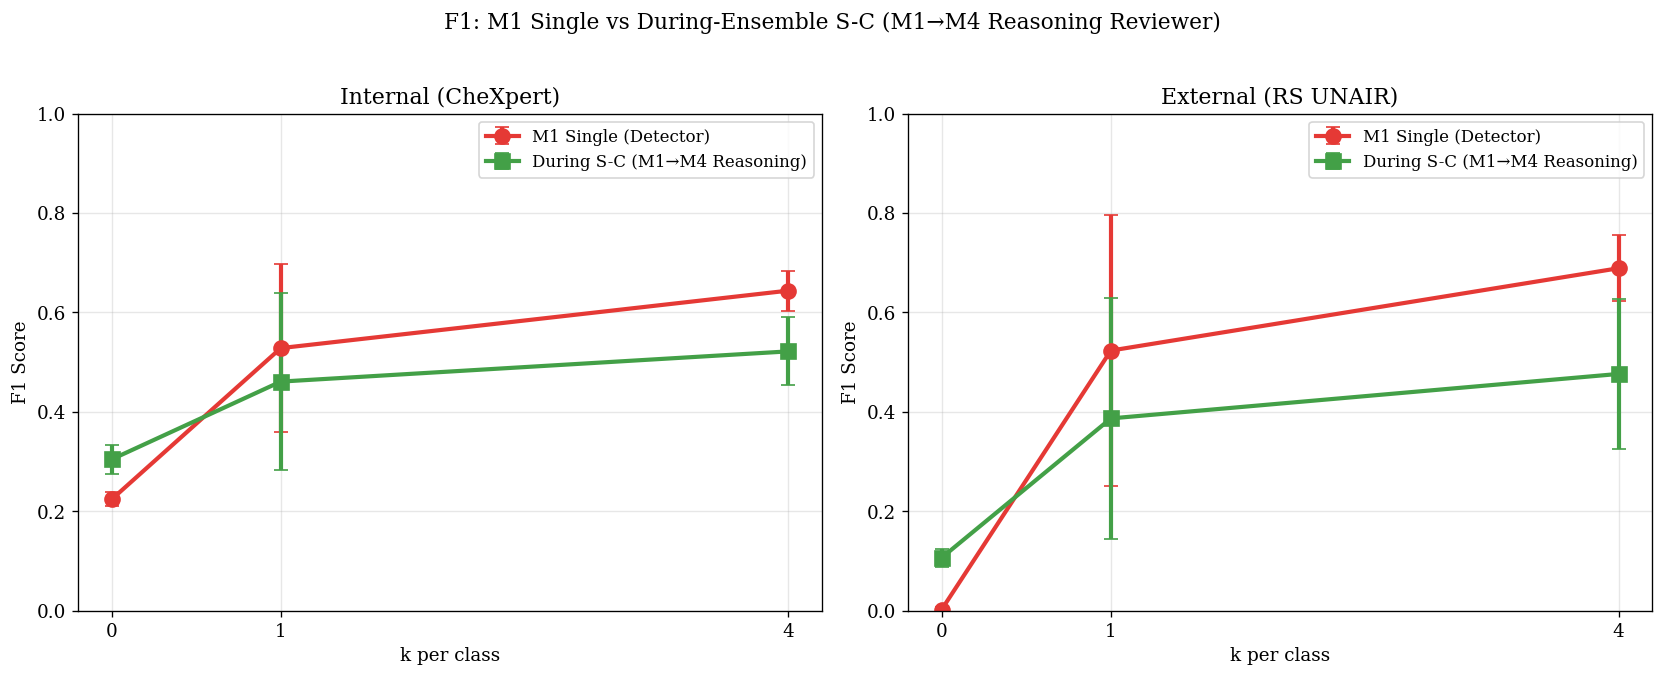

Saved: fig1_f1_reasoning_reviewer


In [18]:
# Fig 1: F1 comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
test_set_names = df_summary['test_set'].unique()

for idx, ts in enumerate(test_set_names):
    ax = axes[idx]
    sub = df_summary[df_summary['test_set'] == ts]
    
    for method in ['M1_single', 'During_M1toM4_Reasoning']:
        s = sub[sub['method'] == method].sort_values('k_shot')
        ax.errorbar(
            s['k_shot'], s['f1_mean'], yerr=s['f1_std'],
            label=METHOD_LABELS.get(method, method),
            marker=METHOD_MARKERS.get(method, 'o'),
            color=METHOD_COLORS.get(method),
            capsize=4, linewidth=2.5, markersize=9,
        )
    
    short_ts = 'Internal (CheXpert)' if 'Internal' in ts else 'External (RS UNAIR)'
    ax.set_xlabel('k per class')
    ax.set_ylabel('F1 Score')
    ax.set_title(short_ts)
    ax.set_xticks(K_SHOTS)
    ax.legend(fontsize=10)
    ax.set_ylim(0, 1.0)

plt.suptitle('F1: M1 Single vs During-Ensemble S-C (M1\u2192M4 Reasoning Reviewer)', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig1_f1_reasoning_reviewer.png', bbox_inches='tight')
plt.savefig(FIGURES_DIR / 'fig1_f1_reasoning_reviewer.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig1_f1_reasoning_reviewer')

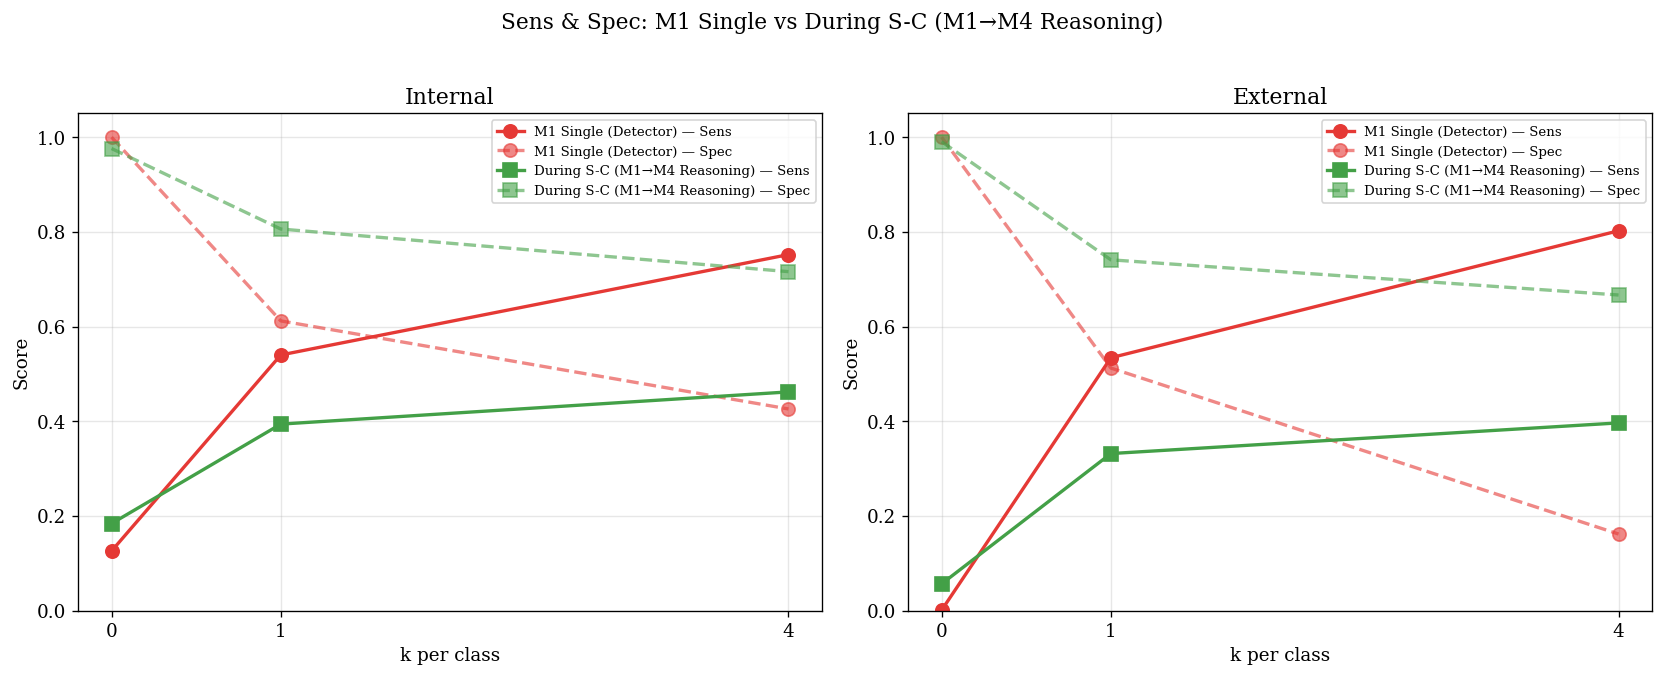

Saved: fig2_sens_spec_reasoning


In [19]:
# Fig 2: Sensitivity & Specificity comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for idx, ts in enumerate(test_set_names):
    ax = axes[idx]
    sub = df_summary[df_summary['test_set'] == ts]
    
    for method in ['M1_single', 'During_M1toM4_Reasoning']:
        s = sub[sub['method'] == method].sort_values('k_shot')
        color = METHOD_COLORS.get(method)
        label = METHOD_LABELS.get(method, method)
        marker = METHOD_MARKERS.get(method, 'o')
        
        ax.plot(s['k_shot'], s['sensitivity_mean'], '-', marker=marker,
                color=color, linewidth=2, markersize=8, label=f'{label} \u2014 Sens')
        ax.plot(s['k_shot'], s['specificity_mean'], '--', marker=marker,
                color=color, linewidth=2, markersize=8, alpha=0.6, label=f'{label} \u2014 Spec')
    
    short_ts = 'Internal' if 'Internal' in ts else 'External'
    ax.set_xlabel('k per class')
    ax.set_ylabel('Score')
    ax.set_title(short_ts)
    ax.set_xticks(K_SHOTS)
    ax.legend(fontsize=8)
    ax.set_ylim(0, 1.05)

plt.suptitle('Sens & Spec: M1 Single vs During S-C (M1\u2192M4 Reasoning)', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig2_sens_spec_reasoning.png', bbox_inches='tight')
plt.savefig(FIGURES_DIR / 'fig2_sens_spec_reasoning.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig2_sens_spec_reasoning')

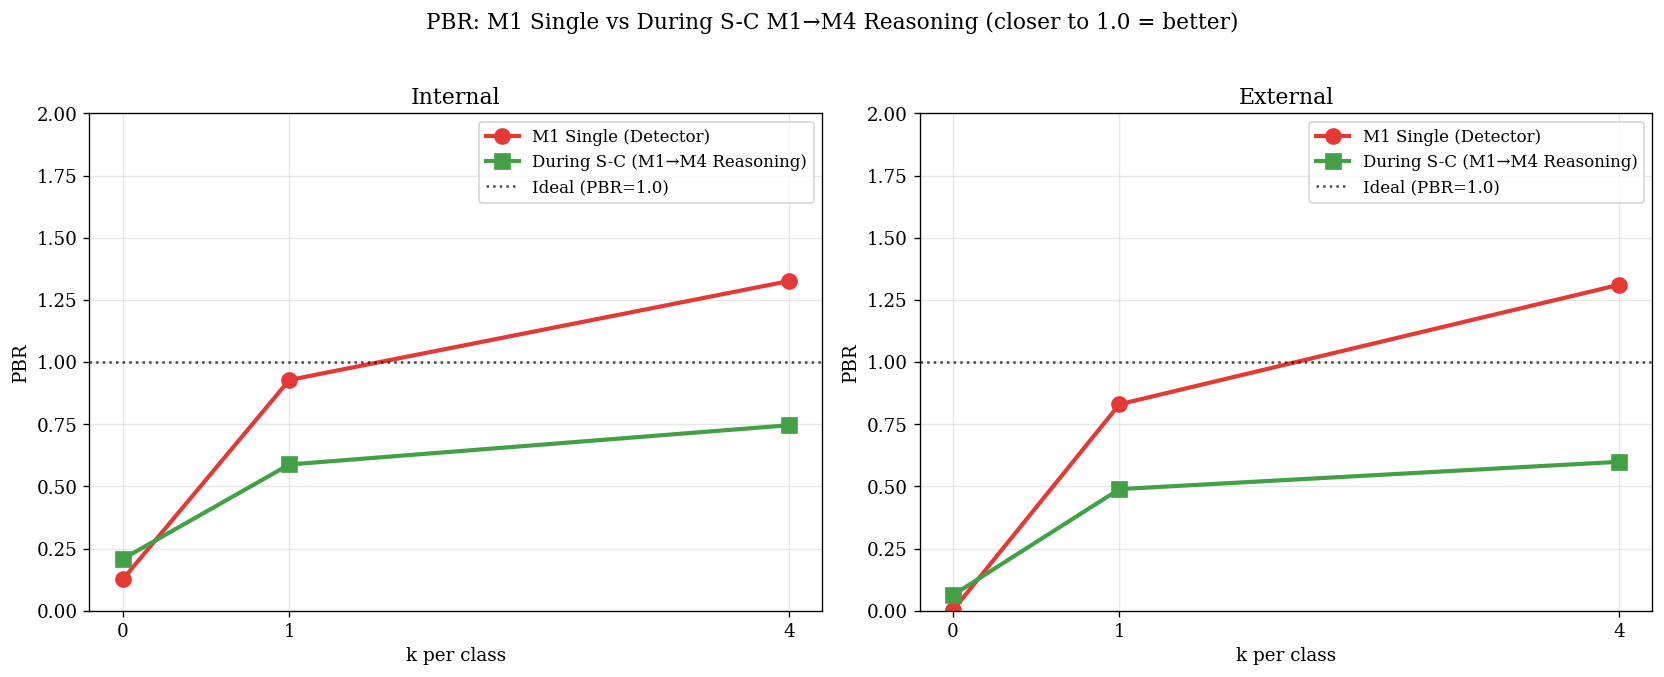

Saved: fig3_pbr_reasoning


In [20]:
# Fig 3: PBR comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for idx, ts in enumerate(test_set_names):
    ax = axes[idx]
    sub = df_summary[df_summary['test_set'] == ts]
    
    for method in ['M1_single', 'During_M1toM4_Reasoning']:
        s = sub[sub['method'] == method].sort_values('k_shot')
        ax.plot(
            s['k_shot'], s['pbr_mean'],
            marker=METHOD_MARKERS.get(method, 'o'),
            color=METHOD_COLORS.get(method),
            label=METHOD_LABELS.get(method, method),
            linewidth=2.5, markersize=9,
        )
    
    ax.axhline(y=1.0, color='black', linewidth=1.5, linestyle=':', alpha=0.7, label='Ideal (PBR=1.0)')
    short_ts = 'Internal' if 'Internal' in ts else 'External'
    ax.set_xlabel('k per class')
    ax.set_ylabel('PBR')
    ax.set_title(short_ts)
    ax.set_xticks(K_SHOTS)
    ax.legend(fontsize=10)
    ax.set_ylim(0, 2.0)

plt.suptitle('PBR: M1 Single vs During S-C M1\u2192M4 Reasoning (closer to 1.0 = better)', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig3_pbr_reasoning.png', bbox_inches='tight')
plt.savefig(FIGURES_DIR / 'fig3_pbr_reasoning.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig3_pbr_reasoning')

Best k for Reasoning Reviewer (by F1 internal): k=4


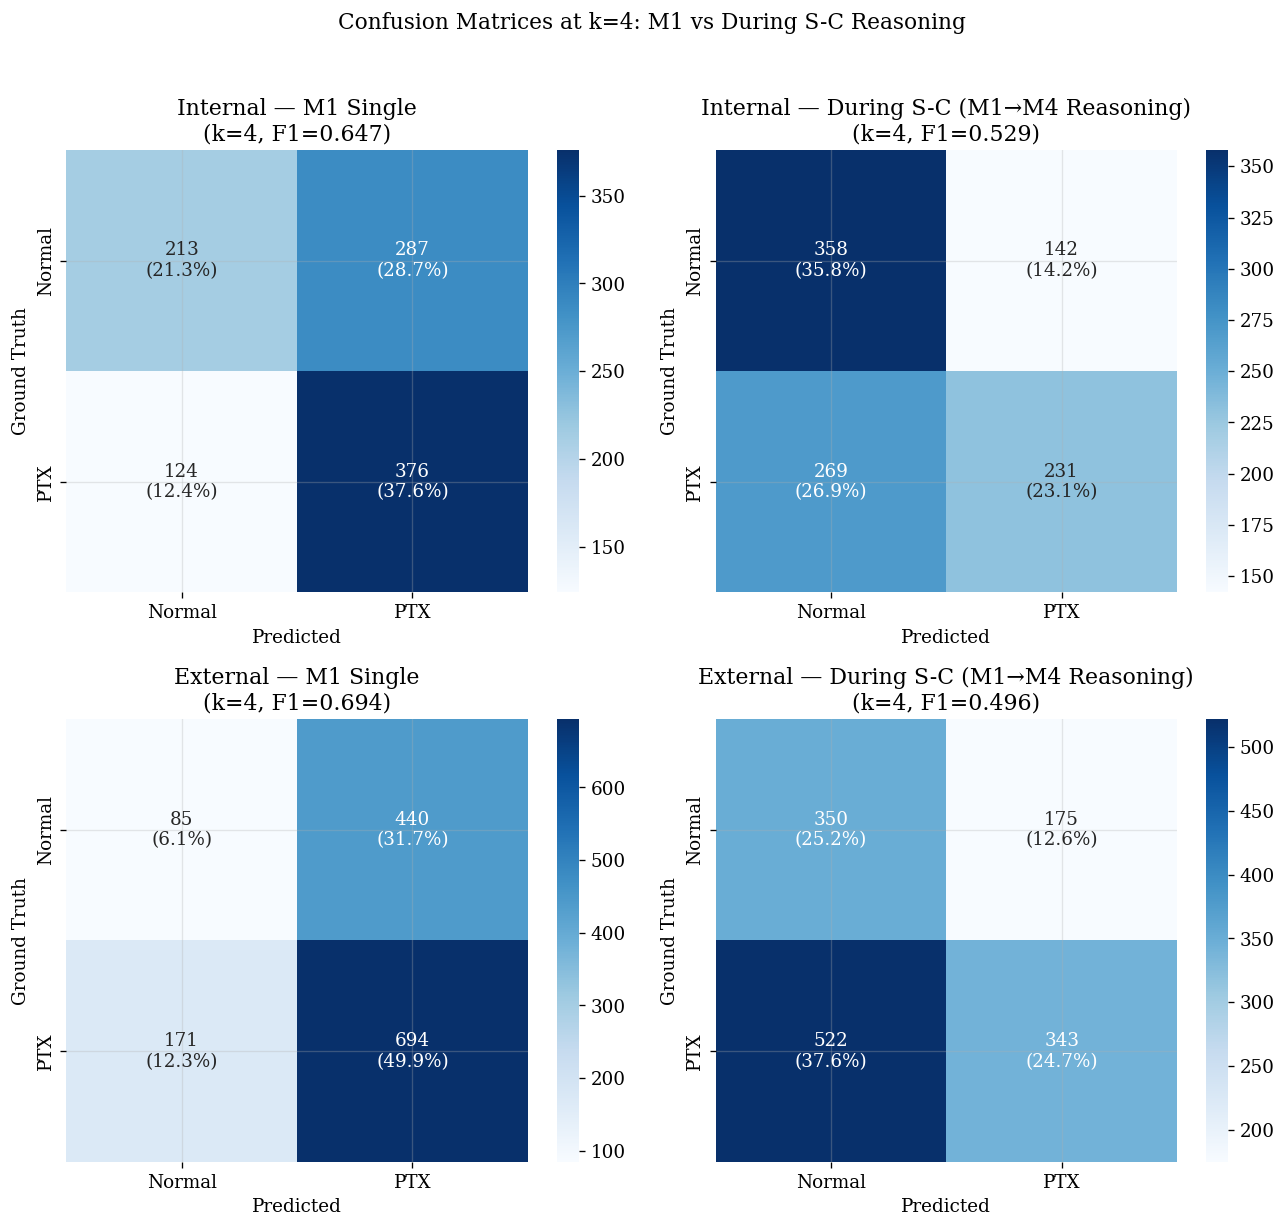

Saved: fig4_confusion_reasoning


In [21]:
# Fig 4: Confusion matrices side-by-side (M1 single vs Reasoning reviewer)
from sklearn.metrics import confusion_matrix as cm_fn, f1_score

# Use best k (by F1) for the comparison
ts_int = [ts for ts in test_set_names if 'Internal' in ts][0]
int_summary = df_summary[(df_summary['test_set'] == ts_int) & (df_summary['method'] == 'During_M1toM4_Reasoning')]
best_k = int(int_summary.loc[int_summary['f1_mean'].idxmax(), 'k_shot'])
print(f"Best k for Reasoning Reviewer (by F1 internal): k={best_k}")

fig, axes = plt.subplots(2, 2, figsize=(11, 10))

configs = [
    ('M1 Single', 'm1_predicted'),
    ('During S-C (M1\u2192M4 Reasoning)', 'm4_predicted'),
]

for ts_idx, ts_name in enumerate(test_set_names):
    sub = df_during[(df_during['k_shot'] == best_k) & (df_during['test_set'] == ts_name)]
    gt = sub['ground_truth'].values
    short_ts = 'Internal' if 'Internal' in ts_name else 'External'
    
    for col_idx, (title, pred_col) in enumerate(configs):
        ax = axes[ts_idx, col_idx]
        preds = sub[pred_col].values
        valid = preds != -1
        cm = cm_fn(gt[valid], preds[valid], labels=[0, 1])
        cm_pct = cm.astype(float) / cm.sum() * 100
        annot = np.array([
            [f'{cm[i,j]}\n({cm_pct[i,j]:.1f}%)' for j in range(2)]
            for i in range(2)
        ])
        sns.heatmap(
            cm, annot=annot, fmt='', cmap='Blues',
            xticklabels=['Normal', 'PTX'],
            yticklabels=['Normal', 'PTX'],
            ax=ax, annot_kws={'fontsize': 11},
        )
        f1 = f1_score(gt[valid], preds[valid], zero_division=0)
        ax.set_xlabel('Predicted')
        ax.set_ylabel('Ground Truth')
        ax.set_title(f'{short_ts} \u2014 {title}\n(k={best_k}, F1={f1:.3f})')

plt.suptitle(f'Confusion Matrices at k={best_k}: M1 vs During S-C Reasoning', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig4_confusion_reasoning.png', bbox_inches='tight')
plt.savefig(FIGURES_DIR / 'fig4_confusion_reasoning.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig4_confusion_reasoning')

## 12 — Statistical Tests

In [22]:
from scipy.stats import wilcoxon

print('=' * 80)
print('STATISTICAL TESTS: During S-C (Reasoning) vs M1 Single (Wilcoxon, per seed)')
print('=' * 80)

for ts in df_metrics['test_set'].unique():
    short_ts = 'Internal' if 'Internal' in ts else 'External'
    print(f'\n--- {short_ts} ---')
    ts_data = df_metrics[df_metrics['test_set'] == ts]
    
    for k in sorted(ts_data['k_shot'].unique()):
        m1_f1 = ts_data[(ts_data['method'] == 'M1_single') & (ts_data['k_shot'] == k)].sort_values('seed')['f1'].values
        ens_f1 = ts_data[(ts_data['method'] == 'During_M1toM4_Reasoning') & (ts_data['k_shot'] == k)].sort_values('seed')['f1'].values
        
        if len(m1_f1) >= 5 and len(ens_f1) >= 5:
            delta = ens_f1 - m1_f1
            mean_delta = delta.mean()
            
            if len(set(delta)) > 1:
                stat, p = wilcoxon(ens_f1, m1_f1)
            else:
                p = 1.0
            
            sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
            print(f'  k={int(k)}: \u0394F1={mean_delta:+.4f}  p={p:.4f} {sig}  '
                  f'(M1={m1_f1.mean():.4f}, Reasoning={ens_f1.mean():.4f})')

STATISTICAL TESTS: During S-C (Reasoning) vs M1 Single (Wilcoxon, per seed)

--- Internal ---
  k=0: ΔF1=+0.0806  p=0.0625 ns  (M1=0.2237, Reasoning=0.3043)
  k=1: ΔF1=-0.0674  p=0.1250 ns  (M1=0.5282, Reasoning=0.4608)
  k=4: ΔF1=-0.1222  p=0.0625 ns  (M1=0.6438, Reasoning=0.5216)

--- External ---
  k=0: ΔF1=+0.1042  p=0.0625 ns  (M1=0.0023, Reasoning=0.1065)
  k=1: ΔF1=-0.1365  p=0.0625 ns  (M1=0.5233, Reasoning=0.3868)
  k=4: ΔF1=-0.2126  p=0.0625 ns  (M1=0.6889, Reasoning=0.4762)


## 13 — Qualitative Analysis: M4 Reasoning ExamplesKarena S-C menghasilkan reasoning, kita bisa analisis **mengapa** M4 setuju/tidak setuju dengan M1.

In [23]:
# Show cases where M1 and M4-reasoning-reviewer disagree
df_during['m1_pred'] = df_during['m1_predicted']
df_during['m4_pred'] = df_during['m4_predicted']
df_during['agree'] = df_during['m1_pred'] == df_during['m4_pred']

# Focus on k=best_k, seed=0, internal
focus = df_during[
    (df_during['k_shot'] == best_k) &
    (df_during['seed'] == 0) &
    (df_during['test_set'].str.contains('Internal'))
]

disagree = focus[~focus['agree']]
print(f"Disagreements at k={best_k}, seed=0, Internal: {len(disagree)} / {len(focus)}")
print(f"Agreement rate: {focus['agree'].mean():.3f}")

# Categorize disagreements
m4_correct = disagree[disagree['m4_pred'] == disagree['ground_truth']]
m1_correct = disagree[disagree['m1_pred'] == disagree['ground_truth']]
print(f"\nWhen they disagree:")
print(f"  M4-reasoning correct: {len(m4_correct)} ({len(m4_correct)/max(len(disagree),1)*100:.1f}%)")
print(f"  M1 correct:           {len(m1_correct)} ({len(m1_correct)/max(len(disagree),1)*100:.1f}%)")

# Show examples WITH M4's reasoning
print(f"\n{'='*80}")
print("DISAGREEMENT EXAMPLES — with M4 reasoning:")
print(f"{'='*80}")

for _, row in disagree.head(5).iterrows():
    gt = 'PTX' if row['ground_truth'] == 1 else 'Normal'
    m1 = 'PTX' if row['m1_pred'] == 1 else 'Normal'
    m4r = 'PTX' if row['m4_pred'] == 1 else 'Normal'
    correct = 'M4-reasoning' if row['m4_pred'] == row['ground_truth'] else 'M1'
    
    print(f"\n  [{row['image_id']}]  GT={gt}  M1={m1}  M4={m4r}  \u2192 {correct} correct")
    print(f"  M4 reasoning output:")
    m4_text = row['m4_generated_text']
    # Show full reasoning (truncated at 500 chars)
    print(f"    {m4_text[:500]}")
    if len(m4_text) > 500:
        print(f"    ...")
    print()

Disagreements at k=4, seed=0, Internal: 41 / 200
Agreement rate: 0.795

When they disagree:
  M4-reasoning correct: 23 (56.1%)
  M1 correct:           18 (43.9%)

DISAGREEMENT EXAMPLES — with M4 reasoning:

  [patient07182_study6_view1_frontal]  GT=PTX  M1=PTX  M4=Normal  → M1 correct
  M4 reasoning output:
    FIRST READER EVALUATION: The first reader has identified a small right pleural effusion and some patchy opacities in the lower lobes. They also noted the presence of support devices.

MY OBSERVATIONS: The image is a single upright PA chest X-ray. The lung fields appear relatively clear, with no obvious consolidation or large masses. There is a small right pleural effusion, which is visible as a blunting of the right costophrenic angle. There are also some patchy opacities in the lower lung zones
    ...


  [patient49769_study2_view1_frontal]  GT=PTX  M1=PTX  M4=Normal  → M1 correct
  M4 reasoning output:
    FIRST READER EVALUATION: The first reader identified a small right api

## 14 — Key Findings

In [24]:
print('=' * 80)
print('KEY FINDINGS \u2014 During-Inference Ensemble S-C (M1\u2192M4 Reasoning Reviewer)')
print('=' * 80)

for ts in df_summary['test_set'].unique():
    short_ts = 'Internal' if 'Internal' in ts else 'External'
    sub = df_summary[df_summary['test_set'] == ts]
    
    print(f'\n--- {short_ts} ---')
    for k in sorted(sub['k_shot'].unique()):
        k_sub = sub[sub['k_shot'] == k]
        m1 = k_sub[k_sub['method'] == 'M1_single'].iloc[0]
        dur = k_sub[k_sub['method'] == 'During_M1toM4_Reasoning'].iloc[0]
        
        f1_delta = dur['f1_mean'] - m1['f1_mean']
        spec_delta = dur['specificity_mean'] - m1['specificity_mean']
        sens_delta = dur['sensitivity_mean'] - m1['sensitivity_mean']
        
        print(f"  k={int(k)}:")
        print(f"    M1 single:       F1={m1['f1_mean']:.3f}  Sens={m1['sensitivity_mean']:.3f}  Spec={m1['specificity_mean']:.3f}  PBR={m1['pbr_mean']:.3f}")
        print(f"    S-C Reasoning:   F1={dur['f1_mean']:.3f}  Sens={dur['sensitivity_mean']:.3f}  Spec={dur['specificity_mean']:.3f}  PBR={dur['pbr_mean']:.3f}")
        print(f"    Delta:           \u0394F1={f1_delta:+.3f}  \u0394Sens={sens_delta:+.3f}  \u0394Spec={spec_delta:+.3f}")

# Inference time comparison
print(f"\n{'='*80}")
print(f"INFERENCE TIME:")
print(f"  Mean: {df_during['m4_inference_time'].mean():.1f}s")
print(f"  Std:  {df_during['m4_inference_time'].std():.1f}s")
print(f"  Compare with S-B (binary gate): ~0.7s")
print(f"{'='*80}")

KEY FINDINGS — During-Inference Ensemble S-C (M1→M4 Reasoning Reviewer)

--- Internal ---
  k=0:
    M1 single:       F1=0.224  Sens=0.126  Spec=1.000  PBR=0.126
    S-C Reasoning:   F1=0.304  Sens=0.184  Spec=0.976  PBR=0.208
    Delta:           ΔF1=+0.081  ΔSens=+0.058  ΔSpec=-0.024
  k=1:
    M1 single:       F1=0.528  Sens=0.540  Spec=0.612  PBR=0.928
    S-C Reasoning:   F1=0.461  Sens=0.394  Spec=0.806  PBR=0.588
    Delta:           ΔF1=-0.067  ΔSens=-0.146  ΔSpec=+0.194
  k=4:
    M1 single:       F1=0.644  Sens=0.752  Spec=0.426  PBR=1.326
    S-C Reasoning:   F1=0.522  Sens=0.462  Spec=0.716  PBR=0.746
    Delta:           ΔF1=-0.122  ΔSens=-0.290  ΔSpec=+0.290

--- External ---
  k=0:
    M1 single:       F1=0.002  Sens=0.001  Spec=1.000  PBR=0.001
    S-C Reasoning:   F1=0.106  Sens=0.057  Spec=0.991  PBR=0.062
    Delta:           ΔF1=+0.104  ΔSens=+0.056  ΔSpec=-0.009
  k=1:
    M1 single:       F1=0.523  Sens=0.534  Spec=0.512  PBR=0.830
    S-C Reasoning:   F1=0.387  S

## 15 — Export

In [25]:
print('EXPORTED FILES:')
print(f'\nResults:')
for f in sorted(OUTPUT_DIR.glob('*')):
    print(f'  {f.name}')
print(f'\nFigures:')
for f in sorted(FIGURES_DIR.glob('fig*')):
    print(f'  {f.name}')

EXPORTED FILES:

Results:
  all_results_during_ensemble_m1_m4_reasoning.jsonl
  checkpoint_during_ensemble_m1_m4_reasoning.jsonl
  during_ensemble_reasoning_per_seed.csv
  during_ensemble_reasoning_summary.csv

Figures:
  fig1_f1_reasoning_reviewer.pdf
  fig1_f1_reasoning_reviewer.png
  fig2_sens_spec_reasoning.pdf
  fig2_sens_spec_reasoning.png
  fig3_pbr_reasoning.pdf
  fig3_pbr_reasoning.png
  fig4_confusion_reasoning.pdf
  fig4_confusion_reasoning.png
